# 03 – Swiss day-ahead price model (agent M2)

Loads the outputs of `python -m src.models.price` and shows the key tables and plots. Nothing is trained here. Full explanation: `reports/model_notes_price.md`.

In [1]:
import os, pandas as pd, joblib
from IPython.display import Image, display, Markdown
os.chdir('..') if os.path.basename(os.getcwd()) == 'notebooks' else None
import src.models.common as common
pd.set_option('display.precision', 2)

## Overall metrics (MAE, RMSE in EUR/MWh; sMAPE in %)

In [2]:
met = pd.read_csv('reports/metrics_price.csv', dtype={'block': str})
allm = met[met.block == 'all']
allm.pivot(index='model', columns='split', values='mae').loc[['naive','linear','rf','gbm','best']]

split,rolling,test,val
model,,,
naive,21.24,23.47,23.54
linear,12.26,12.77,15.16
rf,12.12,16.73,19.01
gbm,10.17,16.82,16.23
best,9.88,10.99,13.62


In [3]:
allm[allm.split.isin(['val','test'])][['split','model','mae','rmse','mape_or_smape','bias','mae_ci_low','mae_ci_high']]

,split,model,mae,rmse,mape_or_smape,bias,mae_ci_low,mae_ci_high
35,val,naive,23.54,29.83,20.97,-7.60,19.29,28.36
42,val,linear,15.16,21.32,14.74,2.14,12.88,17.57
49,val,rf,19.01,26.09,16.98,-1.82,16.27,21.63
56,val,gbm,16.23,21.97,15.16,-1.00,13.70,18.63
63,val,best,13.62,17.98,13.58,-1.44,11.49,15.74
70,test,naive,23.47,33.80,12.89,-19.71,18.36,29.46
77,test,linear,12.77,18.79,6.34,-7.22,10.57,15.14
84,test,rf,16.73,23.03,7.99,-11.73,14.08,19.85
91,test,gbm,16.82,21.86,8.08,-12.15,14.15,19.83
98,test,best,10.99,16.46,5.28,-6.54,9.02,13.18


## Decision metrics (order and shape of the 6 blocks, used by the battery plan)

In [4]:
pd.read_csv('reports/decision_metrics_price.csv').query("split in ['val','test']")

,target,split,model,rank_corr,hit_cheapest,hit_dearest,shape_mae,daymean_mae,n_days
5,price,val,naive,0.89,0.93,0.90,12.64,19.64,30
6,price,val,linear,0.91,0.93,0.93,11.16,12.56,30
7,price,val,rf,0.89,0.93,0.83,14.49,14.73,30
8,price,val,gbm,0.92,0.90,0.87,11.44,12.36,30
9,price,val,best,0.93,0.93,0.97,8.49,11.71,30
10,price,test,naive,0.77,0.65,0.74,14.09,20.50,31
11,price,test,linear,0.89,0.77,0.84,8.77,10.70,31
12,price,test,rf,0.83,0.74,0.81,10.04,13.84,31
13,price,test,gbm,0.88,0.84,0.84,8.50,15.29,31
14,price,test,best,0.89,0.84,0.87,7.37,8.96,31


## Diebold–Mariano tests (negative mean_diff = best is better)

In [5]:
pd.read_csv('reports/model_tests_price.csv')[['split','model_a','model_b','mean_diff','dm_stat','p_value','n_days']]

,split,model_a,model_b,mean_diff,dm_stat,p_value,n_days
0,val,best,naive,-9.92,-3.52,1.44e-03,30
1,val,best,gbm,-2.61,-3.66,1.00e-03,30
2,test,best,naive,-12.47,-4.23,2.03e-04,31
3,test,best,gbm,-5.83,-4.49,9.84e-05,31
4,rolling,best,naive,-11.36,-8.43,1.07e-15,335
5,rolling,best,gbm,-0.29,-0.99,3.24e-01,335


## October 2026: forecast vs actual

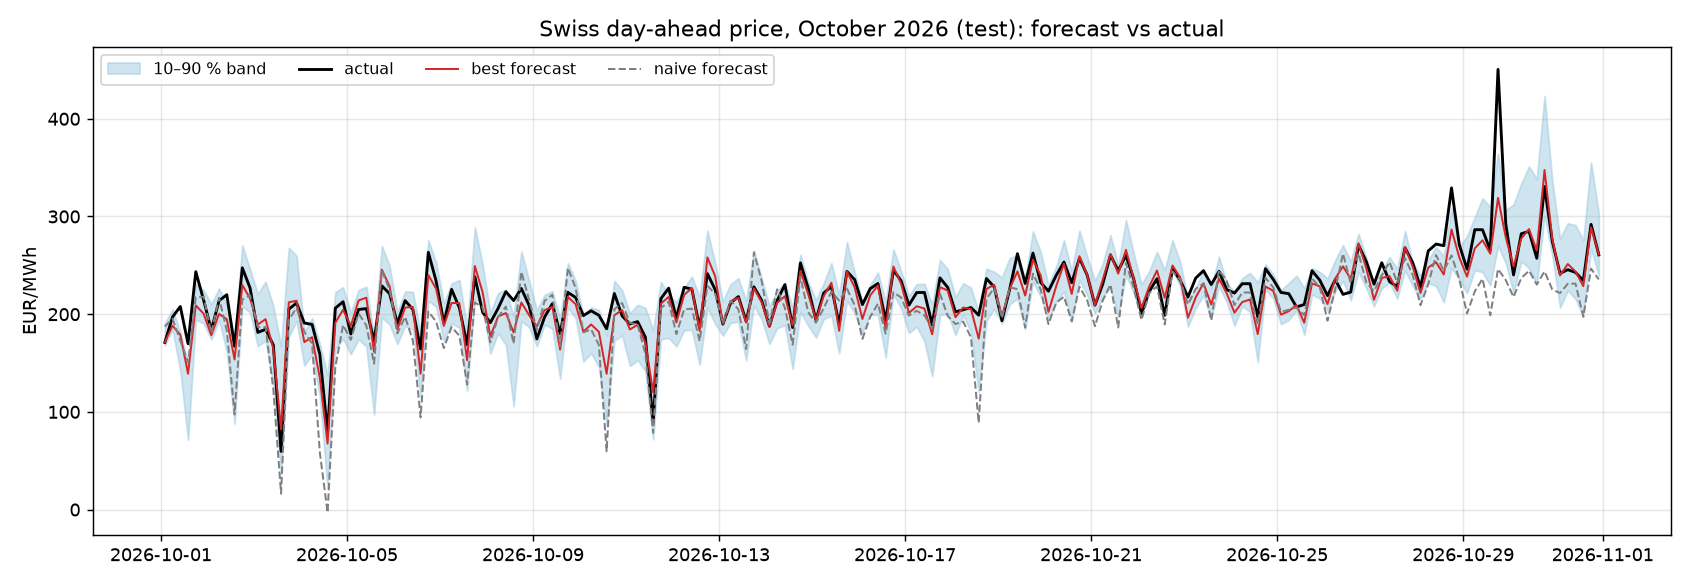

In [6]:
display(Image('reports/figures/price_test_forecast_vs_actual.png'))

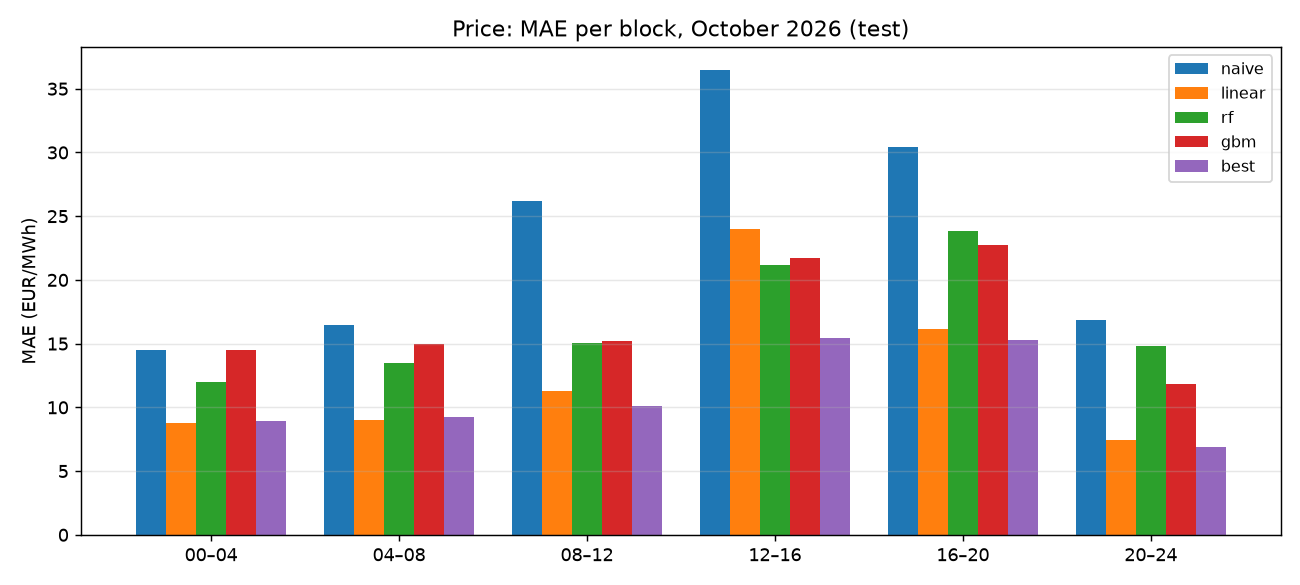

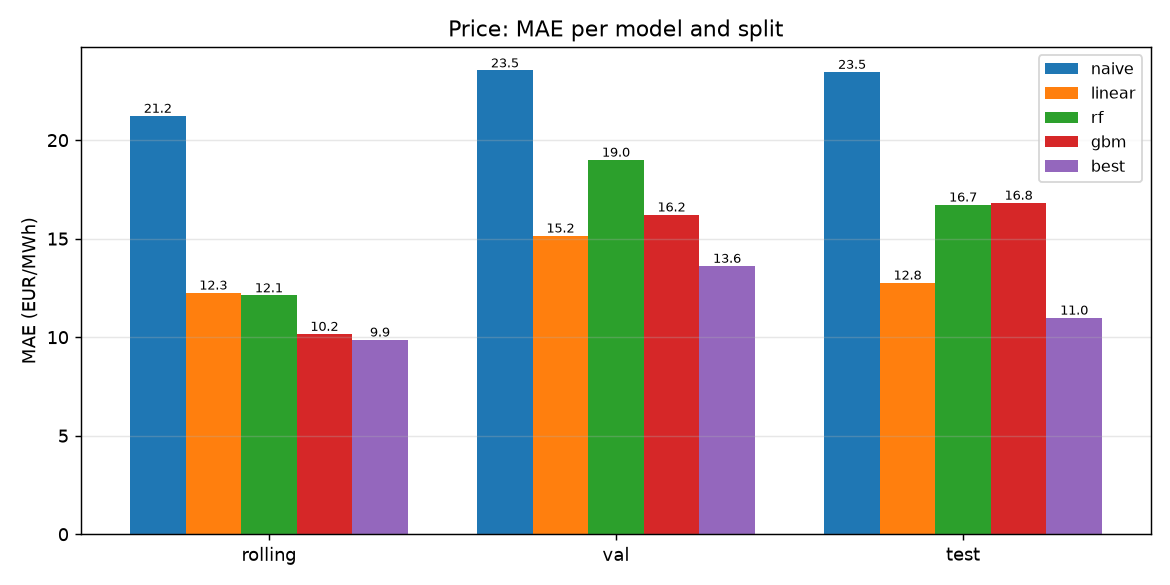

In [7]:
display(Image('reports/figures/price_error_by_block.png'))
display(Image('reports/figures/price_model_ladder.png'))

## The 10 worst test blocks

In [8]:
pd.read_csv('reports/worst_blocks_price.csv')

,delivery_date,block,y_true,pred_best,error,pred_naive,price_lag_1d_same_block,pred_q10,pred_q90,what_happened
0,2026-10-29,4 (16–20),450.56,319.05,-131.51,246.25,329.25,270.19,364.22,Thu; forecast too low; price jumped 121 EUR vs...
1,2026-10-10,3 (12–16),185.02,139.05,-45.97,59.59,180.04,86.58,178.01,Sat; forecast too low
2,2026-10-28,4 (16–20),329.25,286.67,-42.57,260.15,267.98,247.31,308.33,Wed; forecast too low; price jumped 61 EUR vs ...
3,2026-10-01,4 (16–20),243.45,208.98,-34.47,217.44,212.06,194.17,230.98,Thu; forecast too low; large swing inside the ...
4,2026-10-08,3 (12–16),213.93,181.31,-32.62,169.75,168.81,105.82,197.90,Thu; forecast too low; price jumped 45 EUR vs ...
5,2026-10-11,3 (12–16),88.74,120.07,31.33,78.59,185.02,71.79,183.82,Sun; forecast too high; price fell 96 EUR vs s...
6,2026-10-01,3 (12–16),169.75,139.08,-30.68,150.75,128.07,71.35,149.89,Thu; forecast too low; price jumped 42 EUR vs ...
7,2026-10-28,3 (12–16),270.12,240.63,-29.48,244.49,228.29,212.21,259.74,Wed; forecast too low; price jumped 42 EUR vs ...
8,2026-10-01,2 (08–12),207.84,178.90,-28.94,172.83,177.89,142.45,181.78,Thu; forecast too low
9,2026-10-26,2 (08–12),220.31,248.92,28.61,261.91,207.30,233.83,270.53,Mon; forecast too high


## Drivers (permutation importance, Sept + Oct 2026)

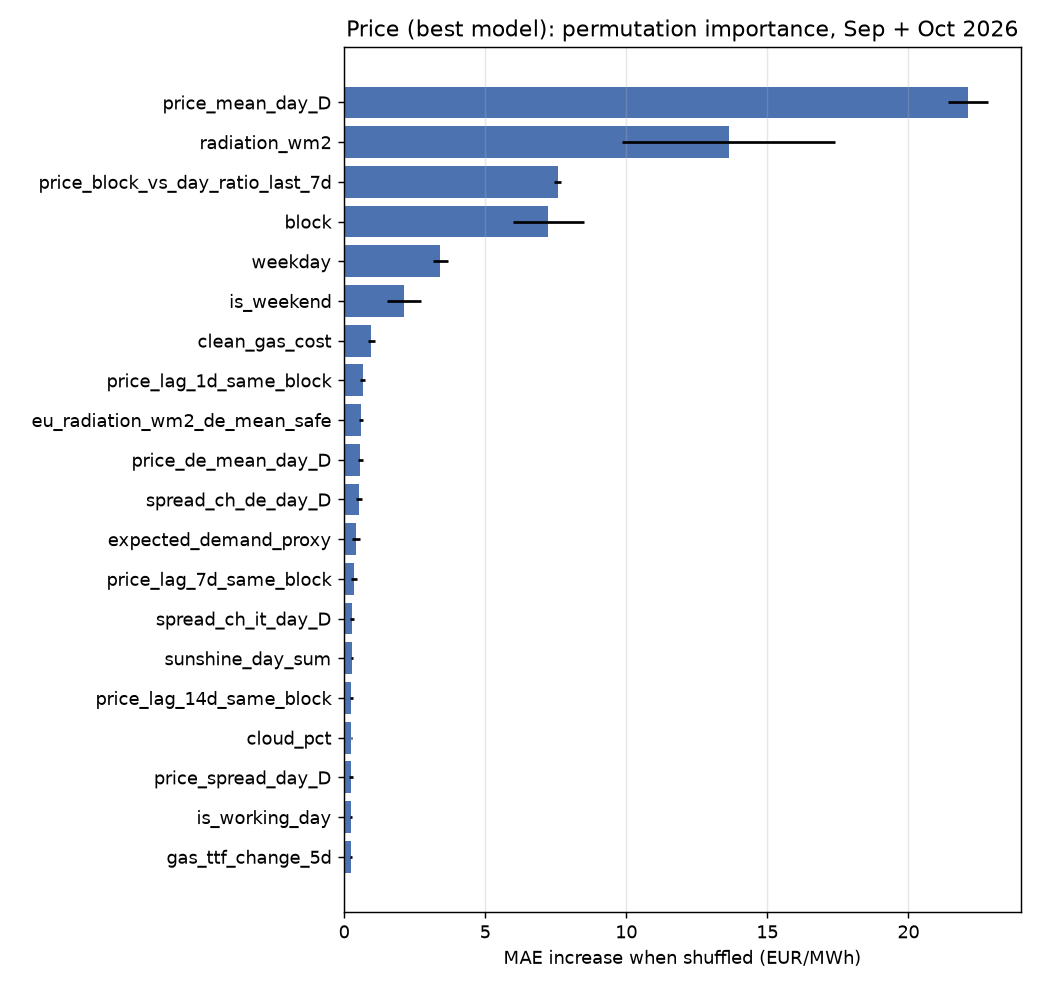

,feature,mae_increase,std,base_mae
0,"CH price of day D (lags, shape)",25.05,1.21,13.0
1,"calendar (block, weekday, holidays, season)",15.11,1.47,13.0
2,Zurich weather (forecast + past observed),14.13,1.32,13.0
3,European weather forecasts JMA (eu_*_jma),2.36,0.30,13.0
4,neighbour prices DE/FR/AT/IT (day D),1.89,0.15,13.0
5,gas / CO2 / EUR-CHF,1.43,0.08,13.0
6,European weather forecasts ICON (eu_*),0.75,0.17,13.0
7,Zurich demand lags,0.44,0.23,13.0
8,"Swiss system D−1 (load, hydro, nuclear, solar)",0.28,0.10,13.0
9,Swiss reservoirs,-0.05,0.01,13.0


In [9]:
display(Image('reports/figures/price_permutation_importance.png'))
pd.read_csv('reports/importance_groups_price.csv')

## What was tried

In [10]:
pd.read_csv('reports/experiments_price.csv')

,experiment,kind,val_mae,val_smape,val_bias,val_rank_corr,val_shape_mae,cv_mae,cv_mae_last2,test_mae,test_smape
0,"A0 LightGBM on the level, equal weights",target,15.42,14.82,-1.07,0.92,10.19,40.99,11.18,NaN,NaN
1,A1 change vs same block of day D,target,15.33,14.68,-3.65,0.93,9.57,12.80,10.97,NaN,NaN
2,A2 change vs day-D mean price,target,14.75,13.62,-2.57,0.94,9.34,13.08,11.19,NaN,NaN
3,A3 change vs day-D mean + 7-day block shape,target,13.89,12.95,-2.92,0.95,8.55,12.61,11.31,NaN,NaN
4,A4 asinh change vs day-D mean + 7-day shape,target,14.52,14.13,-5.28,0.95,8.87,14.09,11.24,NaN,NaN
5,A5 asinh change vs same block of day D,target,15.06,15.04,-6.13,0.92,9.50,15.91,10.80,NaN,NaN
6,B0 no recency weights,recency,14.12,13.22,-3.08,0.94,9.14,12.65,11.47,NaN,NaN
7,B1 recency half-life 0.5 y,recency,14.64,13.31,-3.94,0.94,8.93,13.00,11.29,NaN,NaN
8,B2 recency half-life 1.5 y,recency,14.03,12.36,-3.30,0.94,8.79,12.71,11.36,NaN,NaN
9,B3 recency half-life 2 y,recency,14.37,13.01,-3.54,0.94,8.68,12.54,11.13,NaN,NaN


## The saved model works on new rows

In [11]:
m = joblib.load('models/price_best.joblib')
oct_rows = common.split_frame(common.load_features(), 'test')
out = oct_rows[['delivery_date','block']].assign(forecast=m.predict(oct_rows))
out = pd.concat([out, m.predict_quantiles(oct_rows)], axis=1)
out.head(12)

,delivery_date,block,forecast,pred_q10,pred_q50,pred_q90
16896,2026-10-01,0,171.14,168.02,175.45,190.72
16897,2026-10-01,1,188.26,183.98,190.24,205.09
16898,2026-10-01,2,178.90,142.45,173.81,181.78
16899,2026-10-01,3,139.08,71.35,136.46,149.89
16900,2026-10-01,4,208.98,194.17,206.69,230.98
16901,2026-10-01,5,200.59,190.85,197.14,224.50
16902,2026-10-02,0,178.51,174.25,180.55,210.45
16903,2026-10-02,1,200.28,193.63,202.68,226.28
16904,2026-10-02,2,194.85,161.51,184.62,209.46
16905,2026-10-02,3,153.64,87.84,141.37,176.78
